# Beat 9: Testes de sanidade — isso é fiel ao modelo?

**Pergunta:** o mapa depende dos **pesos** da rede, ou sairia igual com qualquer
modelo?

**Tempo:** 3 min. Depende da Fase 10 (`gradcam.sanity`,
`scripts/11_sanity_checks.py`).

O Grad-CAM é vendido como explicação *do modelo*. Se o mapa não mudasse ao
destruir os pesos, não explicaria nada — seria um detector de bordas. É a
crítica de Adebayo et al. (2018), e é o contra-argumento que fecha a apresentação.

In [1]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import json

import matplotlib.pyplot as plt

# Nenhum número é digitado: a curva vem do JSON gravado pelo script.
metrics_path = os.path.join("results", "metrics", "sanity_cascade.json")
if not os.path.exists(metrics_path):
    metrics_path = os.path.join("..", "results", "metrics", "sanity_cascade.json")

with open(metrics_path, "r", encoding="utf-8") as handle:
    measured = json.load(handle)

print(
    f"modelo {measured['model']} | {measured['n_parameters_modules']} camadas com "
    f"parâmetros | {len(measured['images'])} imagens | semente {measured['seed']}"
)
print("cascade (topo -> base):", " -> ".join(measured["order"][:5]), "...")

modelo vgg16 | 16 camadas com parâmetros | 2 imagens | semente 0
cascade (topo -> base): classifier.6 -> classifier.3 -> classifier.0 -> features.28 -> features.26 ...


## O protocolo: randomizar de cima para baixo

1. calcula o mapa no modelo treinado;
2. reamostra os pesos da **última** camada com parâmetros, depois da
   penúltima, e assim por diante até a primeira `conv` — sempre **cumulativo**;
3. recalcula o mapa com a mesma imagem e a **mesma classe** e mede
   `|Spearman|` contra o original.

O módulo entra na conta porque um modelo randomizado pode inverter o sinal do
gradiente; a pergunta é se a **estrutura** do mapa sobreviveu. Também importa
*quando* ela cai: `k` é o número de camadas já randomizadas.

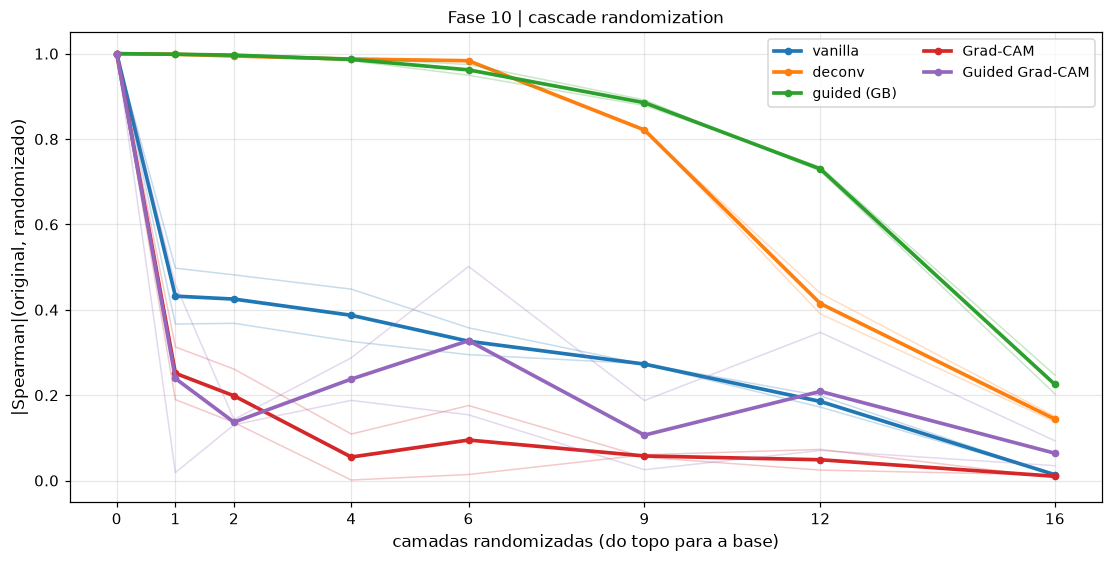

vanilla            final 0.014 | 1o k com |rho| < 0,5: 1, 1 | monotônica: sim
deconv             final 0.144 | 1o k com |rho| < 0,5: 12, 12 | monotônica: sim
guided (GB)        final 0.225 | 1o k com |rho| < 0,5: 16, 16 | monotônica: sim
Grad-CAM           final 0.010 | 1o k com |rho| < 0,5: 1, 1 | monotônica: não
Guided Grad-CAM    final 0.064 | 1o k com |rho| < 0,5: 1, 1 | monotônica: não


In [2]:
labels = {
    "vanilla": "vanilla",
    "deconv": "deconv",
    "guided": "guided (GB)",
    "gradcam": "Grad-CAM",
    "guided_gradcam": "Guided Grad-CAM",
}

fig, ax = plt.subplots(figsize=(10, 5), dpi=110, layout="constrained")
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
cutoffs = measured["cutoffs"]

for color, method in zip(colors, measured["images"][0]["curves"]):
    per_image = [
        [step["abs_spearman"] for step in image["curves"][method]["steps"]]
        for image in measured["images"]
    ]
    for values in per_image:
        ax.plot(cutoffs, values, color=color, alpha=0.25, linewidth=1)
    mean = [
        sum(values[i] for values in per_image) / len(per_image)
        for i in range(len(cutoffs))
    ]
    ax.plot(
        cutoffs, mean, color=color, linewidth=2.4, marker="o", markersize=4,
        label=labels.get(method, method),
    )

ax.set_xlabel("camadas randomizadas (do topo para a base)", fontsize=11)
ax.set_ylabel("|Spearman|(original, randomizado)", fontsize=11)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(cutoffs)
ax.grid(alpha=0.3)
ax.set_title("Fase 10 | cascade randomization", fontsize=11)
ax.legend(fontsize=9, ncols=2)
plt.show()

for method, stats in measured["summary"].items():
    halves = ", ".join(
        "nunca" if half is None else str(half)
        for half in stats["k_first_below_0p5_per_image"]
    )
    print(
        f"{labels.get(method, method):18s} final {stats['mean_abs_spearman_final']:.3f} "
        f"| 1o k com |rho| < 0,5: {halves} | monotônica: "
        f"{'sim' if stats['monotonic_all_images'] else 'não'}"
    )

**A ordem das curvas é o resultado, e ela tem duas partes.**

1. **O que depende do classificador morre no primeiro passo.** Com só a última
   camada (`classifier.6`, o `Linear` final) randomizada em `k = 1`, o Grad-CAM cai
   para 0,31 e 0,19 nas duas imagens (média 0,25) e o Guided Grad-CAM para 0,02 e
   0,46 — média 0,24, com variância enorme, porque o produto herda a fragilidade do
   Grad-CAM. As três saliências por gradiente ficam em 1,00: elas não usam a camada
   final.
2. **O que sobrevive é a borda da entrada.** `guided` e `deconv` só perdem metade
   da correlação no fim do cascade (`k = 12–16`), quando as primeiras `conv`
   também já são ruído. Nesse ponto o mapa é a imagem filtrada, não a rede.

Isso é o mesmo achado de Adebayo et al., e o inverso do que a estética sugere: o
mapa "bonito" do Guided Backprop é o menos fiel ao modelo.

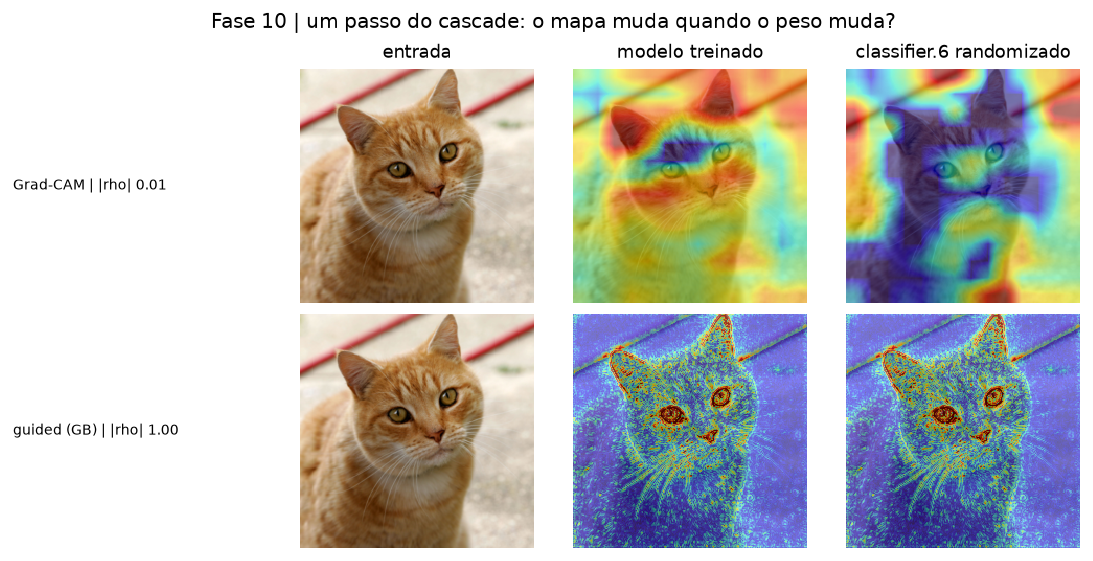

classe 285 | randomizado: classifier.6 | |rho| Grad-CAM 0.012 | |rho| guided 1.000


In [3]:
import torch
from PIL import Image

from gradcam.metrics import gradcam_map_fn, saliency_map_fn, spearman
from gradcam.models import denormalize, load_model, predict, preprocess
from gradcam.sanity import cascade, randomization_order
from gradcam.viz import figure_grid, overlay, tensor_to_numpy

# Demonstração ao vivo com uma imagem só, para olhar o efeito (o número canônico
# é o do JSON). Mostramos o PRIMEIRO passo do cascade: randomizar a última camada
# já separa os dois grupos, e o mapa continua legível. No fim do cascade o
# Grad-CAM degenera (mapa constante), e aí o Spearman nem está definido.
base = "notebooks/assets" if os.path.isdir("notebooks/assets") else "assets"
x = preprocess(Image.open(os.path.join(base, "cat_dog.jpg")).convert("RGB"))
image_rgb = tensor_to_numpy(denormalize(x))

model = load_model("vgg16")
class_idx = int(predict(model, x, topk=1)[0][0])

gc, gb = gradcam_map_fn(), saliency_map_fn("guided")
before = {name: fn(model, x, class_idx).detach() for name, fn in (("gc", gc), ("gb", gb))}

order = randomization_order(model)
cascade(model, order, 1, torch.Generator().manual_seed(measured["seed"]))
after = {name: fn(model, x, class_idx).detach() for name, fn in (("gc", gc), ("gb", gb))}

rho_gc = abs(spearman(before["gc"], after["gc"]))
rho_gb = abs(spearman(before["gb"], after["gb"]))

fig = figure_grid(
    [
        [
            image_rgb,
            overlay(image_rgb, before["gc"], high=0.99, gamma=0.5),
            overlay(image_rgb, after["gc"], high=0.99, gamma=0.5),
        ],
        [
            image_rgb,
            overlay(image_rgb, before["gb"], high=0.99, gamma=0.5),
            overlay(image_rgb, after["gb"], high=0.99, gamma=0.5),
        ],
    ],
    col_titles=("entrada", "modelo treinado", f"{order[0][0]} randomizado"),
    row_titles=[f"Grad-CAM | |rho| {rho_gc:.2f}", f"guided (GB) | |rho| {rho_gb:.2f}"],
    suptitle="Fase 10 | um passo do cascade: o mapa muda quando o peso muda?",
)
plt.show()

print(
    f"classe {class_idx} | randomizado: {order[0][0]} | "
    f"|rho| Grad-CAM {rho_gc:.3f} | |rho| guided {rho_gb:.3f}"
)

**Takeaway:** um mapa que não muda quando o modelo muda não é uma explicação do
modelo. O Grad-CAM passa no teste — mas por um motivo específico: ele morre
quando a **cabeça** da rede morre, porque seus pesos vêm do gradiente da camada
final. As saliências por gradiente resistem muito mais tempo: o que sobra nelas
é a borda da entrada.

A figura acima mostra só o primeiro passo, para o mapa continuar legível. Na
curva completa o Grad-CAM já está praticamente zerado em `k = 4` (0,11 e 0,00 nas
duas imagens) e no fim do cascade o mapa degenera: rodando o cascade inteiro com
o `cat_dog`, o mapa fica **constante** e o `|rho|` deixa de estar definido — por
isso a demonstração para no primeiro passo. O 0,010 do JSON é a média de duas
imagens em que ainda sobrou alguma variação. A curva está no gráfico e o número
canônico em `results/metrics/sanity_cascade.json`.

Isso reposiciona o Guided Grad-CAM: a localização vem de um termo frágil
(Grad-CAM) e o detalhe de um termo quase insensível aos pesos (GB). A composição
é boa *para olhar*, e a bateria de números é quem decide o resto.

Escopo declarado: a *data randomization* do artigo exigiria retreinar o modelo com
rótulos embaralhados, e não há treino neste repositório — só a randomização de
parâmetros é reproduzida. Fonte: `results/metrics/sanity_cascade.json`.